## Brick segmenter trained on digital towers
Plan: **where** each brick is comes from a segmenter trained on rendered towers (exact masks, even for same-colored neighbours, which is where SAM merged bricks). **What** each brick is stays with the lookup (gallery of real table photos).
1. Render many random towers on random backgrounds with shadows, exposure, blur and noise.
2. Train a one-class (`brick`) YOLO11 segmenter on them.
3. Run it on the real photos in `real/` and name every mask with the lookup.

Limits: the camera is orthographic (no perspective) and the render look is plastic-clean. The only judge is the real photos, so look at the last picture.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, sys, cv2, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '.'); import ldraw_render as R

ld = {r['bricklink_name']: int(r['ldraw_code']) for r in csv.DictReader(open('data/lego_colors.csv'))}   # element_map.csv uses the BrickLink color names
PARTS = []   # the pieces as (LDraw part, LDraw color); a part the LDraw library lacks is skipped (6178pr0002, the 6x12 plate, is not in the towers anyway)
for r in csv.DictReader(open('data/element_map.csv')):
    try: R.flatten(r['part_num'] + '.dat'); PARTS.append((r['part_num'], ld[r['color']]))
    except (FileNotFoundError, KeyError) as e: print('skipped', r['part_num'], r['color'], '-', repr(e))
print(len(PARTS), 'pieces')

skipped 6178pr0002 Light Bluish Gray - FileNotFoundError('LDraw file not found: 6178pr0002.dat')
44 pieces


train 0 / 1200
train 100 / 1200
train 200 / 1200
train 300 / 1200
train 400 / 1200
train 500 / 1200
train 600 / 1200
train 700 / 1200
train 800 / 1200
train 900 / 1200
train 1000 / 1200
train 1100 / 1200
val 0 / 150
val 100 / 150
1200 train + 150 val images in yolo_tower/persp


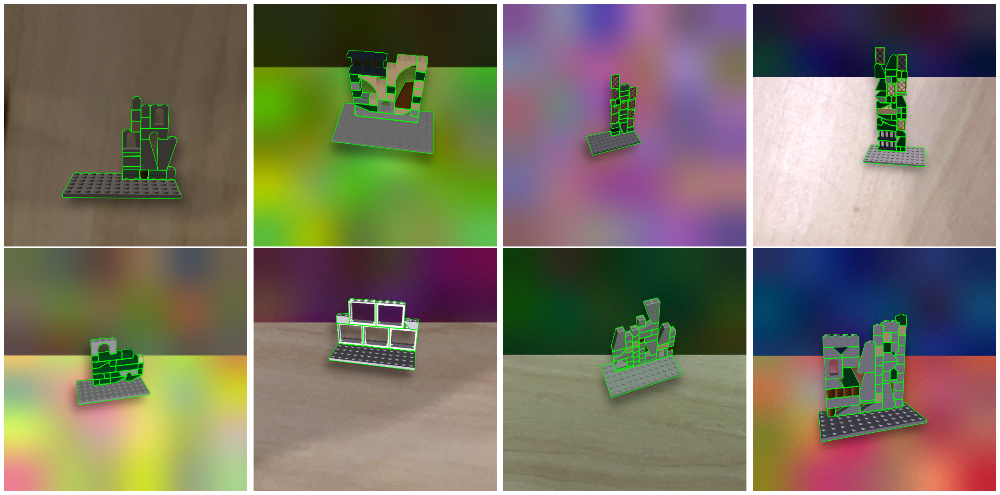

In [2]:
# 1. Render the training set: tower -> picture + exact id mask -> composite on a background -> YOLO polygons (class 0 = brick).
# Matches real/image copy.png: perspective phone camera, level to ~50 degrees above, tower on the 6x12 base plate, small in the frame.
# Resumable: every image has its own seed, and an image whose .jpg + .txt already exist is skipped (so a crash costs nothing). Delete yolo_tower/persp to redo from scratch.
import gc
YT, SIZE, N_TRAIN, N_VAL = 'yolo_tower/persp', 640, 1200, 150   # new folder: the old orthographic set in yolo_tower/ is not mixed in
tbl = list(csv.DictReader(open('data/boxes.csv')))

def table_patch(rng, size):   # a patch of a real table photo that does not contain the brick
    for _ in range(20):
        r = tbl[rng.integers(len(tbl))]; im = cv2.imread(r['path'], cv2.IMREAD_REDUCED_COLOR_4)   # 1/4 size, EXIF is stripped so no rotation surprises
        if im is None: continue
        x0, y0, x1, y1 = (float(r[k]) / 4 for k in ('x0', 'y0', 'x1', 'y1')); s = int(rng.integers(300, min(im.shape[:2]) - 10))
        px, py = int(rng.integers(0, im.shape[1] - s)), int(rng.integers(0, im.shape[0] - s))
        if px + s < x0 or px > x1 or py + s < y0 or py > y1: return cv2.resize(im[py:py + s, px:px + s], (size, size))[..., ::-1]
    return None

def noise_bg(rng, size):   # smooth random colour blobs + grain: desk, wall, cloth ...
    bg = cv2.resize(rng.normal(size=(6, 6, 3)), (size, size), interpolation=cv2.INTER_CUBIC)
    return np.clip(rng.uniform(40, 220, 3) + 25 * bg + rng.normal(0, 3, (size, size, 3)), 0, 255).astype(np.uint8)

def compose(rgba, rng, size):
    bg = table_patch(rng, size) if rng.random() < .5 else None
    bg = noise_bg(rng, size) if bg is None else bg
    if rng.random() < .5:   # like the photos: a dark busy band (keyboard / monitor) across the top, table below
        top = (noise_bg(rng, size) * rng.uniform(0.2, 0.7)).astype(np.uint8); h = int(size * rng.uniform(0.25, 0.5)); bg = bg.copy(); bg[:h] = top[:h]
    a = rgba[..., 3:] / 255.0
    sh = cv2.GaussianBlur(np.roll(a[..., 0], (int(rng.integers(8, 30)), int(rng.integers(-20, 20))), (0, 1)), (0, 0), 12)[..., None]   # soft shadow under/behind
    im = (bg * (1 - 0.4 * sh)) * (1 - a) + rgba[..., :3] * a
    im = im * rng.uniform(0.7, 1.2) * rng.uniform(0.9, 1.1, 3)   # exposure + white balance
    if rng.random() < .5: im = cv2.GaussianBlur(im, (0, 0), rng.uniform(0.5, 1.8))
    return np.clip(im + rng.normal(0, rng.uniform(0, 5), im.shape), 0, 255).astype(np.uint8)

def polygons(ids, size):
    out = []
    for n in np.unique(ids)[1:]:
        m = (ids == n).astype(np.uint8)
        if m.sum() < 150: continue   # too small to label
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); c = cv2.approxPolyDP(max(cs, key=cv2.contourArea), 1.0, True)[:, 0]
        if len(c) >= 3: out.append('0 ' + ' '.join(f'{x / size:.5f} {y / size:.5f}' for x, y in c))
    return out

def make_split(name, n, seed):
    for sub in ('images', 'labels'): os.makedirs(f'{YT}/{name}/{sub}', exist_ok=True)
    for i in range(n):
        img_f, lab_f = f'{YT}/{name}/images/{i:05d}.jpg', f'{YT}/{name}/labels/{i:05d}.txt'
        if os.path.exists(img_f) and os.path.exists(lab_f): continue   # already rendered (resume after a crash)
        rng = np.random.default_rng([seed, i])
        tower = R.make_tower(PARTS, rng, plate=True); rgba, ids = R.render_scene(tower, size=SIZE, rng=rng)
        open(lab_f, 'w').write('\n'.join(polygons(ids, SIZE)))
        cv2.imwrite(img_f, compose(rgba, rng, SIZE)[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 92])   # image last: its presence = the pair is complete
        del tower, rgba, ids
        if i % 100 == 0: gc.collect(); print(name, i, '/', n)

if not os.path.exists(f'{YT}/data.yaml'):
    make_split('train', N_TRAIN, 10); make_split('val', N_VAL, 11)
    open(f'{YT}/data.yaml', 'w').write(f'path: {os.path.abspath(YT)}\ntrain: train/images\nval: val/images\nnames:\n  0: brick\n')
print(len(os.listdir(f'{YT}/train/images')), 'train +', len(os.listdir(f'{YT}/val/images')), 'val images in', YT)

fig, ax = plt.subplots(2, 4, figsize=(24, 12))   # look at a few: image + its polygons
for a, f in zip(ax.flat, sorted(os.listdir(f'{YT}/val/images'))[:8]):
    im = cv2.cvtColor(cv2.imread(f'{YT}/val/images/{f}'), cv2.COLOR_BGR2RGB); a.imshow(im); a.axis('off')
    for line in open(f'{YT}/val/labels/{f[:-4]}.txt').read().split('\n'):
        if line: p = np.array(line.split()[1:], float).reshape(-1, 2) * SIZE; a.add_patch(plt.Polygon(p, fill=False, color='lime', lw=1))
plt.tight_layout(); plt.show()

In [3]:
# 2. Train a one-class (brick) YOLO11 segmenter on the rendered towers (skipped if runs/tower_seg/weights/best.pt exists).
# Starts from the box detector's yolo11s.pt backbone if that file is in the repo root (no download); otherwise from scratch (slower to converge: more epochs, or put yolo11s-seg.pt in the repo root).
# Gentle on the PC: batch 8, 4 workers, no RAM cache. Close other GPU notebooks first (the desktop shares this GPU).
from ultralytics import YOLO
BEST = 'runs/segment/runs/tower_seg/weights/best.pt'   # ultralytics nests relative project dirs, as in autolabel.ipynb
if not os.path.exists(BEST) and not os.path.exists('runs/tower_seg/weights/best.pt'):
    if os.path.exists('yolo11s-seg.pt'): m = YOLO('yolo11s-seg.pt')
    else:
        m = YOLO('yolo11s-seg.yaml')
        if os.path.exists('yolo11s.pt'): m.load('yolo11s.pt')
    m.train(data=f'{YT}/data.yaml', imgsz=SIZE, epochs=60, batch=8, workers=4, cache=False, project='runs', name='tower_seg', exist_ok=True, plots=True, verbose=False)
BEST = next(p for p in (BEST, 'runs/tower_seg/weights/best.pt') if os.path.exists(p)); print('using', BEST)
mv = YOLO(BEST).val(data=f'{YT}/data.yaml', imgsz=SIZE, batch=8, workers=4, verbose=False)
print(f'val (digital towers only, so optimistic): box mAP50 {mv.box.map50:.3f} | mask mAP50 {mv.seg.map50:.3f} mAP50-95 {mv.seg.map:.3f}')

using runs/segment/runs/tower_seg/weights/best.pt
Ultralytics 8.4.216 🚀 Python-3.12.16 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060, 11928MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3018.5±877.9 MB/s, size: 69.5 KB)
val: Scanning /home/denkata/Desktop/Lego Fusion Battle Towers Model/yolo_tower/persp/val/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.8Kit/s 0.1s
val: New cache created: /home/denkata/Desktop/Lego Fusion Battle Towers Model/yolo_tower/persp/val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 8.2it/s 2.3s<0.2s
                   all        150       4646      0.839      0.732      0.823      0.615      0.832      0.707      0.792      0.437
Speed: 0.7ms preprocess, 7.4ms inference, 0.0ms loss, 1.3ms postprocess per imag

real/image copy 2.png: 20 masks | similarity median 0.85 | >= 0.93: 0, 0.85-0.93: 11, < 0.85: 9   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)


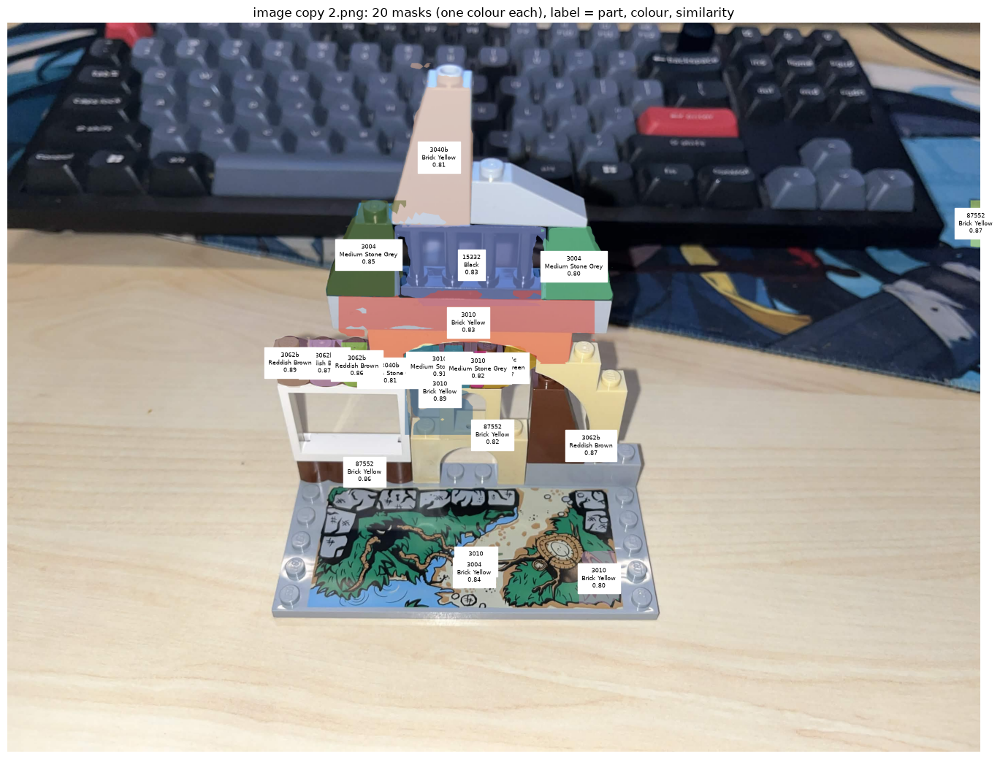

real/image copy 3.png: 24 masks | similarity median 0.85 | >= 0.93: 0, 0.85-0.93: 14, < 0.85: 10   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)


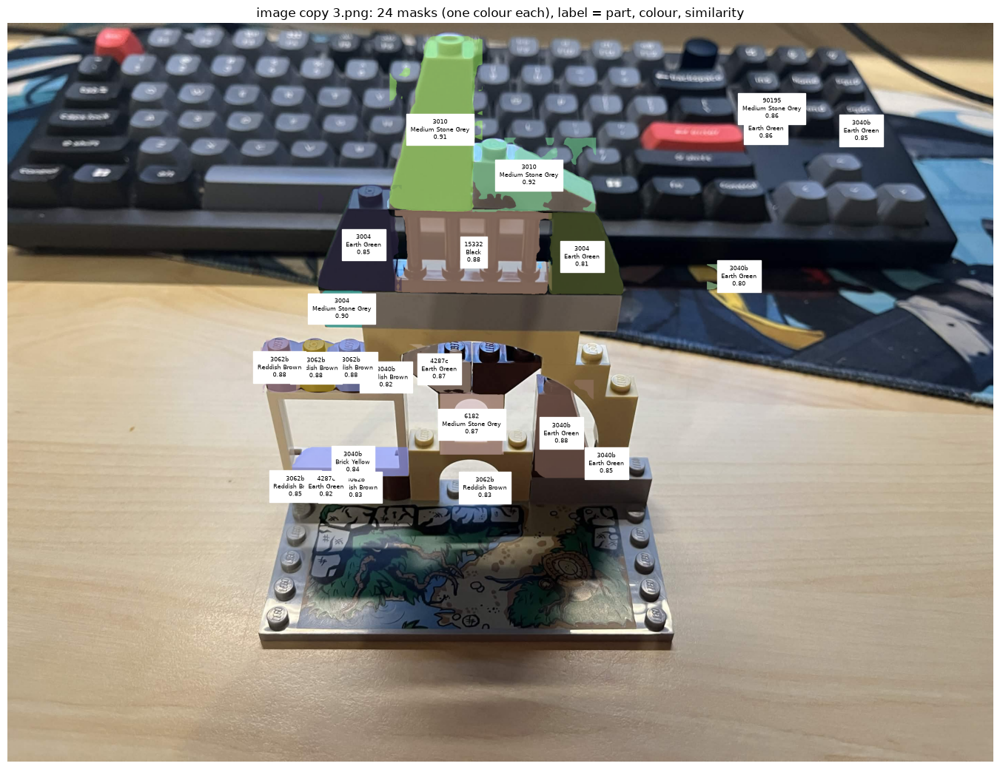

real/image copy.png: 20 masks | similarity median 0.85 | >= 0.93: 0, 0.85-0.93: 11, < 0.85: 9   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)


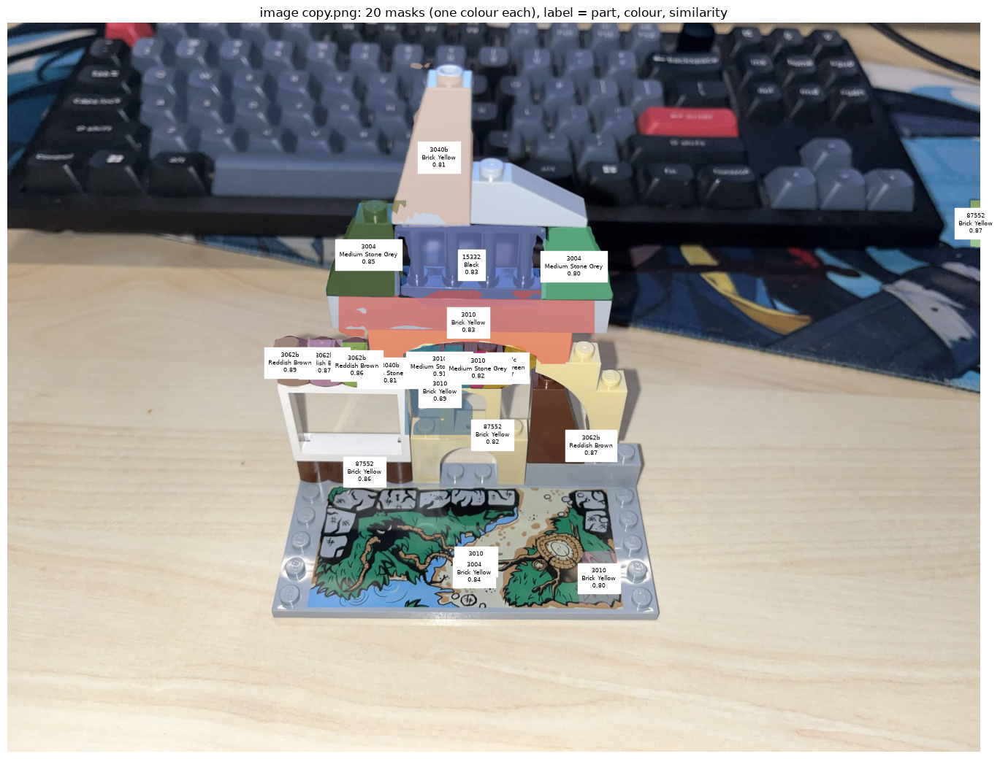

real/image.png: 57 masks | similarity median 0.84 | >= 0.93: 0, 0.85-0.93: 28, < 0.85: 29   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)


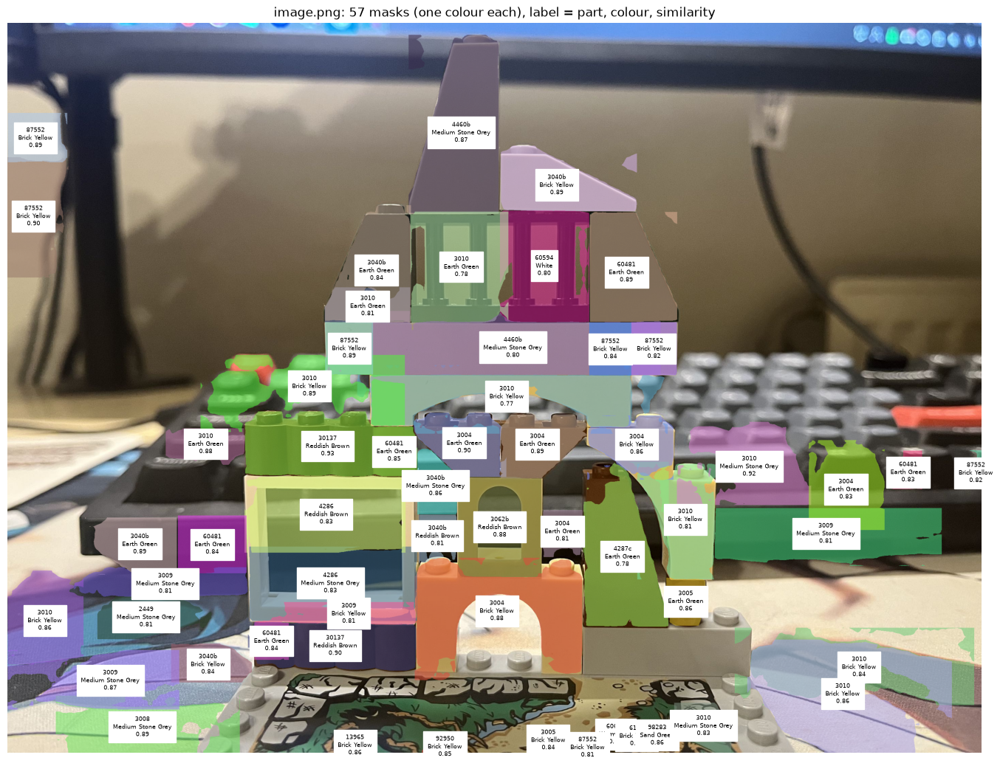

output/image_tower.png: 56 masks | similarity median 0.83 | >= 0.93: 0, 0.85-0.93: 14, < 0.85: 42   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)


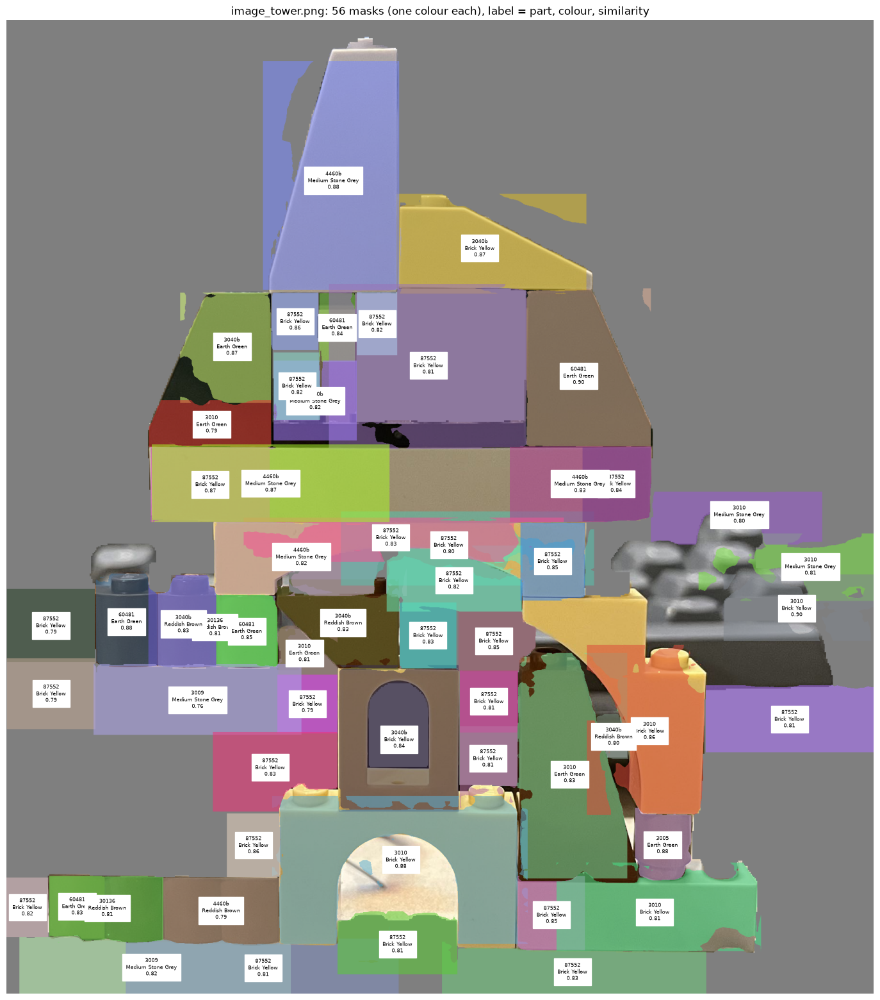

In [4]:
# 3. The real test: segment every real photo in real/ (and the cleaned tower crop, if test_real.ipynb made one), name each mask with the lookup.
# Colours differ per mask (not by similarity) so same-coloured neighbours are visible as separate bricks. Saved to output/<photo>_seg.png.
import glob, lego_lookup as L
seg = YOLO(BEST); emb, gal = L.load_embedder(), L.load_gallery()
cname = {r['lego_id']: r['lego_name'] for r in csv.DictReader(open('data/lego_colors.csv'))}
srcs = sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]')) + sorted(glob.glob('output/*_tower.png'))
for f in srcs:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    r = seg.predict(img[..., ::-1], imgsz=1024, conf=0.2, retina_masks=True, verbose=False)[0]
    if r.masks is None: print(f, ': no masks'); continue
    ms = r.masks.data.cpu().numpy() > 0.5; crops = []
    for m in ms:
        ys, xs = np.where(m); bx = (xs.min(), ys.min(), xs.max(), ys.max()); mm = L.crop_box(m.astype(np.uint8) * 255, *bx) > 127
        crops.append(np.where(mm[..., None], L.crop_box(img, *bx), 127).astype(np.uint8))
    res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True, shape_min_sim=-1)
    sims = np.array([x[1] for x in res])
    print(f'{f}: {len(ms)} masks | similarity median {np.median(sims):.2f} | >= 0.93: {(sims >= .93).sum()}, 0.85-0.93: {((sims >= .85) & (sims < .93)).sum()}, < 0.85: {(sims < .85).sum()}   (SAM on the cleaned tower: 39 masks, median 0.80, none >= 0.93)')
    over = img.copy(); rng = np.random.default_rng(0)
    for m in ms: over[m] = (0.45 * over[m] + 0.55 * rng.integers(40, 255, 3)).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(14, 14 * img.shape[0] / img.shape[1])); ax.imshow(over); ax.axis('off')
    for m, (shape, sim, col, _) in zip(ms, res):
        ys, xs = np.where(m); ax.text(xs.mean(), ys.mean(), f'{shape}\n{cname.get(col, col)}\n{sim:.2f}', color='black', fontsize=6, backgroundcolor='white', ha='center', va='center')
    ax.set_title(f'{os.path.basename(f)}: {len(ms)} masks (one colour each), label = part, colour, similarity'); plt.tight_layout()
    fig.savefig(f'output/{os.path.splitext(os.path.basename(f))[0]}_seg.png', dpi=80, bbox_inches='tight'); plt.show()

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

{'status': 'ok', 'restart': False}

: 